# Probabilistic FDM — Burgers方程式 (Laplace近似)

PDE: $\partial_t u + u\partial_x u = \nu\partial_{xx} u$, 
$u(0,x)=\sin(\pi x)$, $u(t,0)=u(t,1)=0$

- 時間: Backward Euler
- 空間: 非線形項は中心差分、拡散項は中心差分
- 各時間ステップでNewton法
- 事後分布: Laplace近似（MAP + ヘッセアン逆行列）

In [59]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Statistics

## 1. Matérnカーネル・問題設定

In [60]:
function matern_kernel(x1, x2; ν=1.0, ℓ=1.0)
    r = abs(x1 - x2)
    r == 0 && return 1.0
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return exp(-z)
    elseif ν == 1.5
        return (1 + z) * exp(-z)
    elseif ν == 2.5
        return (1 + z + z^2/3) * exp(-z)
    else
        return (2^(1-ν) / gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix(X1, X2; ν=1.0, ℓ=1.0)
    [matern_kernel(x1, x2; ν=ν, ℓ=ℓ) for x1 in X1, x2 in X2]
end

# 問題設定
ν_pde = 0.01 / π   # 粘性係数
u0_func(x) = sin(π * x)   # 初期条件

u0_func (generic function with 1 method)

## 2. Burgers方程式の残差・ヤコビアン (各時間ステップ)

In [61]:
# ============================================================
# 各時間ステップで解く非線形系:
#   F(u^n) := (I - dt*ν*Δ_h) u^n + dt*(u^n ⊙ D_x u^n) - u^{n-1} = 0
#
# Backward Euler + 中心差分:
#   拡散項: ν*(u_{i-1} - 2u_i + u_{i+1})/dx^2
#   移流項: u_i*(u_{i+1} - u_{i-1})/(2dx)
# ============================================================

function burgers_residual(u_new, u_old, dx, dt, ν_pde)
    n = length(u_new)
    F = zeros(n)
    # 境界条件
    F[1]   = u_new[1]    # u(t,0) = 0
    F[end] = u_new[end]  # u(t,1) = 0
    # 内点
    for i in 2:n-1
        diff_term  = ν_pde * (u_new[i-1] - 2u_new[i] + u_new[i+1]) / dx^2
        adv_term   = u_new[i] * (u_new[i+1] - u_new[i-1]) / (2dx)
        F[i] = u_new[i] - u_old[i] - dt * (diff_term - adv_term)
    end
    return F
end

function burgers_jacobian(u, dx, dt, ν_pde)
    n = length(u)
    J = zeros(n, n)
    # 境界
    J[1,1]     = 1.0
    J[end,end] = 1.0
    # 内点
    for i in 2:n-1
        # ∂F_i/∂u_{i-1}
        J[i,i-1] = -dt * (ν_pde/dx^2 + u[i]/(2dx))
        # ∂F_i/∂u_i
        J[i,i]   =  1.0 + dt * (2ν_pde/dx^2 + (u[i+1]-u[i-1])/(2dx))
        # ∂F_i/∂u_{i+1}
        J[i,i+1] = -dt * (ν_pde/dx^2 - u[i]/(2dx))
    end
    return J
end

# Newton法で各時間ステップを解く
function newton_step(u_old, dx, dt, ν_pde; tol=1e-10, maxiter=50)
    u = copy(u_old)
    for _ in 1:maxiter
        F = burgers_residual(u, u_old, dx, dt, ν_pde)
        J = burgers_jacobian(u, dx, dt, ν_pde)
        δu = J \ (-F)
        u .+= δu
        norm(δu) < tol && break
    end
    return u
end

newton_step (generic function with 1 method)

## 3. Laplace近似による事後分布

In [62]:
# ============================================================
# Laplace近似:
#   MAP推定 û = Newton法の収束点 (= 標準FDM解)
#   û の周りで線形化: F(u) ≈ F(û) + J(u - û) = J(u - û)
#   (F(û) ≈ 0 なので)
#
#   線形観測モデル: J u = J û + ε, ε ~ N(0, Σ_noise)
#   これはGP回帰と同じ形: 観測 y = J û, 情報オペレータ = J
#
#   事後平均: μ_post = K J^T (J K J^T + Σ_noise)^{-1} (J û)
#   事後共分散: Σ_post = K - K J^T (J K J^T + Σ_noise)^{-1} J K
# ============================================================

function laplace_posterior(u_map, u_old, x_all, dx, dt, ν_pde;
                            ℓ, C, h, τ, ν_ker=1.0)
    n   = length(u_map)
    J   = burgers_jacobian(u_map, dx, dt, ν_pde)

    # GP事前共分散
    K = Symmetric(kernel_matrix(x_all, x_all; ν=ν_ker, ℓ=ℓ) + 1e-8*I)

    # 観測ノイズ: 内点は C*h^{2τ}, 境界は極小 (完全観測に近い)
    noise_var  = C * h^(2τ)
    noise_diag = [i == 1 || i == n ? 1e-10 : noise_var for i in 1:n]
    Σ_noise    = Diagonal(noise_diag)

    # 線形化された観測: y = J * û
    y_lin = J * u_map

    # GP事後分布 (線形観測モデル):
    # Woodbury: M = J K J^T + Σ_noise
    JK = J * K
    M  = Symmetric(JK * J' + Σ_noise + 1e-10*I)
    L  = cholesky(M).L
    α  = L' \ (L \ y_lin)

    # 事後平均
    μ_post = K * J' * α

    # 事後共分散
    V      = L \ JK          # (J K J^T + Σ)^{-1/2} J K
    Σ_post = K - V' * V

    std_post = sqrt.(max.(diag(Σ_post), 0.0))
    return μ_post, std_post, Σ_post
end


laplace_posterior (generic function with 1 method)

## 5. 実験: 時間発展 + Laplace近似

## 4. リファレンス解の計算

In [63]:
# ============================================================
# リファレンス解: 細かいグリッド (Nx_ref=500, Nt_ref=2000) で計算
# これを「真の解」として使用
# ============================================================
Nx_ref = 500
Nt_ref = 2000
dx_ref = 1.0 / Nx_ref
dt_ref = T / Nt_ref
x_ref  = collect(0.0:dx_ref:1.0)

u_ref = zeros(Nt_ref+1, Nx_ref+1)
u_ref[1, :] = u0_func.(x_ref)
for n in 1:Nt_ref
    u_ref[n+1, :] = newton_step(u_ref[n,:], dx_ref, dt_ref, ν_pde)
end
println("Reference solution computed (Nx=$(Nx_ref), Nt=$(Nt_ref))")

# リファレンス解を粗いグリッドに補間 (最近傍)
# x_all の各点に対して x_ref の最近傍インデックスを取得
function interp_ref(u_ref_row, x_ref, x_query)
    [u_ref_row[argmin(abs.(x_ref .- xq))] for xq in x_query]
end

# 各時刻でのリファレンス解 (粗いグリッド上に補間)
# t_ref_steps[n] が t = n*dt に対応するリファレンスのステップ
t_ref_step(n) = round(Int, n * dt / dt_ref)  # 粗いグリッドの時刻に対応するref step

u_true_coarse = zeros(Nt+1, Nx+1)
for n in 0:Nt
    ref_idx = clamp(t_ref_step(n), 1, Nt_ref+1)
    u_true_coarse[n+1, :] = interp_ref(u_ref[ref_idx, :], x_ref, x_all)
end
println("Reference interpolated to coarse grid.")

Reference solution computed (Nx=500, Nt=2000)
Reference interpolated to coarse grid.


In [65]:
# ============================================================
# 設定
# ============================================================
Nx      = 5       # 空間グリッド数 (粗め: shockでの不確実性を可視化)
Nt      = 5        # 時間ステップ数
T       = 0.5       # 終端時刻
dx      = 1.0 / Nx
dt      = T / Nt
h       = dx        # 代表刻み幅
ν_ker   = 1.0       # Matérn smoothness
τ_fixed = 2
ℓ_fixed = 0.5       # 長さスケール (dx=0.2より大きく)
C_fixed = 1.0       # ノイズスケール

x_all = collect(0.0:dx:1.0)   # Nx+1 点

# 時間発展
u_all = zeros(Nt+1, Nx+1)
u_all[1, :] = u0_func.(x_all)

for n in 1:Nt
    u_all[n+1, :] = newton_step(u_all[n,:], dx, dt, ν_pde)
end
println("Newton iterations done.")

# Laplace近似 (各時間ステップ)
μ_all   = zeros(Nt+1, Nx+1)
std_all = zeros(Nt+1, Nx+1)
μ_all[1,:]   = u_all[1,:]
std_all[1,:] = zeros(Nx+1)   # t=0は初期条件既知

for n in 1:Nt
    μ, σ, _ = laplace_posterior(
        u_all[n+1,:], u_all[n,:], x_all, dx, dt, ν_pde;
        ℓ=ℓ_fixed, C=C_fixed, h=h, τ=τ_fixed, ν_ker=ν_ker
    )
    μ_all[n+1,:]   = μ
    std_all[n+1,:] = σ
end
println("Laplace approximation done.")

Newton iterations done.
Laplace approximation done.


## 6. 可視化: 4パネル (t=0, T/3, 2T/3, T)

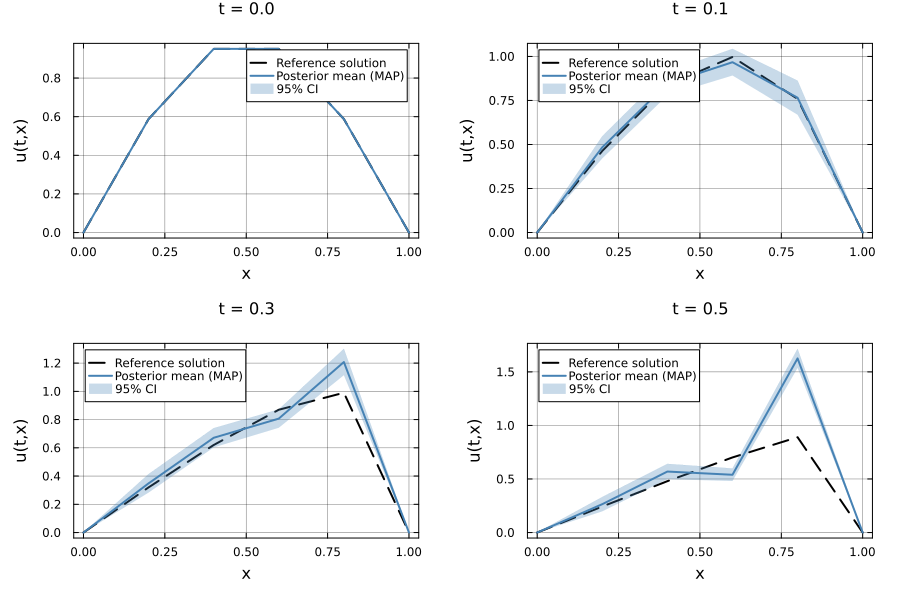

Saved: burgers_laplace_4panels.png


In [66]:
plot_steps = unique([0, div(Nt,3), div(2Nt,3), Nt])
plots_list = []

for n in plot_steps
    t_n  = n * dt
    μ_n  = μ_all[n+1, :]
    σ_n  = std_all[n+1, :]

    u_ref_n = u_true_coarse[n+1, :]

    p = plot(
        x_all, u_ref_n;
        label="Reference solution",
        lw=2, ls=:dash, color=:black,
        xlabel="x", ylabel="u(t,x)",
        title="t = $(round(t_n, digits=3))",
        titlefontsize=11, legendfontsize=8,
        grid=true, gridalpha=0.3, framestyle=:box,
    )
    plot!(p, x_all, μ_n;
        label="Posterior mean (MAP)", lw=2, color=:steelblue
    )
    # fillrange を別の書き方に変更 (Plots.jl の互換性対応)
    plot!(p, x_all, μ_n .+ 1.96.*σ_n;
        lw=0, fillalpha=0, label=false, color=:steelblue)
    plot!(p, x_all, μ_n .- 1.96.*σ_n;
        lw=0, fillrange=μ_n .+ 1.96.*σ_n,
        fillalpha=0.3, linealpha=0,
        label="95% CI", color=:steelblue
    )
    push!(plots_list, p)
end

fig = plot(
    plots_list...;
    layout=(2,2), size=(900,600), margin=5Plots.mm
)
display(fig)
savefig(fig, "burgers_laplace_4panels.png")
println("Saved: burgers_laplace_4panels.png")

## 7. 可視化: 時空間ヒートマップ

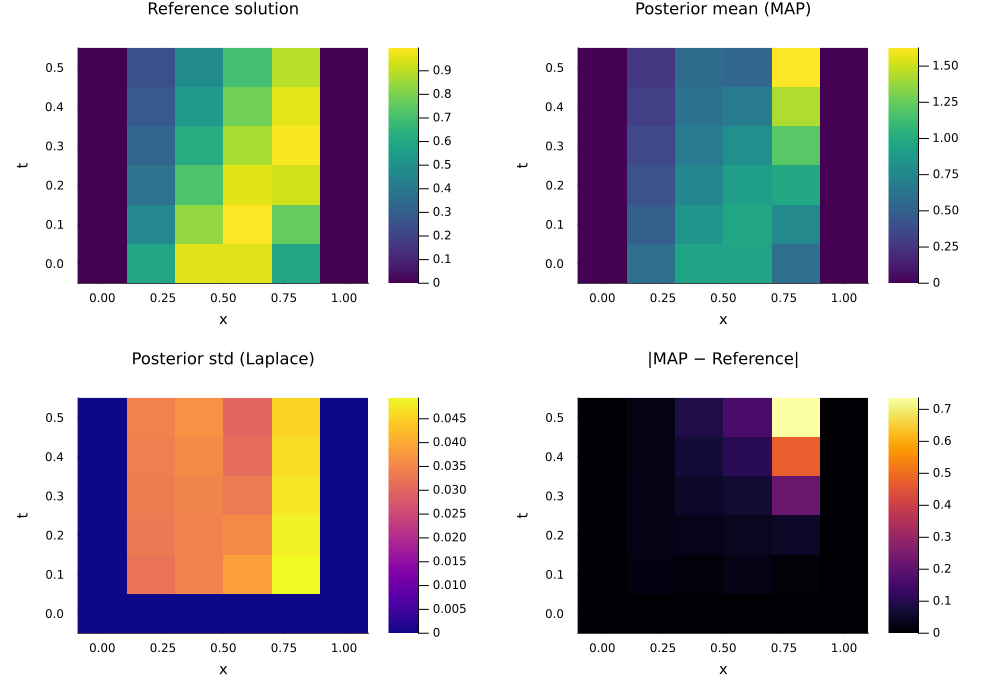

Saved: burgers_laplace_heatmap.png


In [67]:
t_grid = [n*dt for n in 0:Nt]

p1 = heatmap(x_all, t_grid, u_true_coarse;
    xlabel="x", ylabel="t", title="Reference solution",
    color=:viridis,
    titlefontsize=11, guidefontsize=10,
)
p2 = heatmap(x_all, t_grid, μ_all;
    xlabel="x", ylabel="t", title="Posterior mean (MAP)",
    color=:viridis,
    titlefontsize=11, guidefontsize=10,
)
p3 = heatmap(x_all, t_grid, std_all;
    xlabel="x", ylabel="t", title="Posterior std (Laplace)",
    color=:plasma,
    titlefontsize=11, guidefontsize=10,
)
p4 = heatmap(x_all, t_grid, abs.(μ_all .- u_true_coarse);
    xlabel="x", ylabel="t", title="|MAP − Reference|",
    color=:inferno,
    titlefontsize=11, guidefontsize=10,
)

fig_hm = plot(p1, p2, p3, p4; layout=(2,2), size=(1000,700), margin=6Plots.mm)
display(fig_hm)
savefig(fig_hm, "burgers_laplace_heatmap.png")
println("Saved: burgers_laplace_heatmap.png")